Enter your U.S. Census API key: ··········
County data saved to: /content/bachelors_degree_county_data_2015_2019.csv


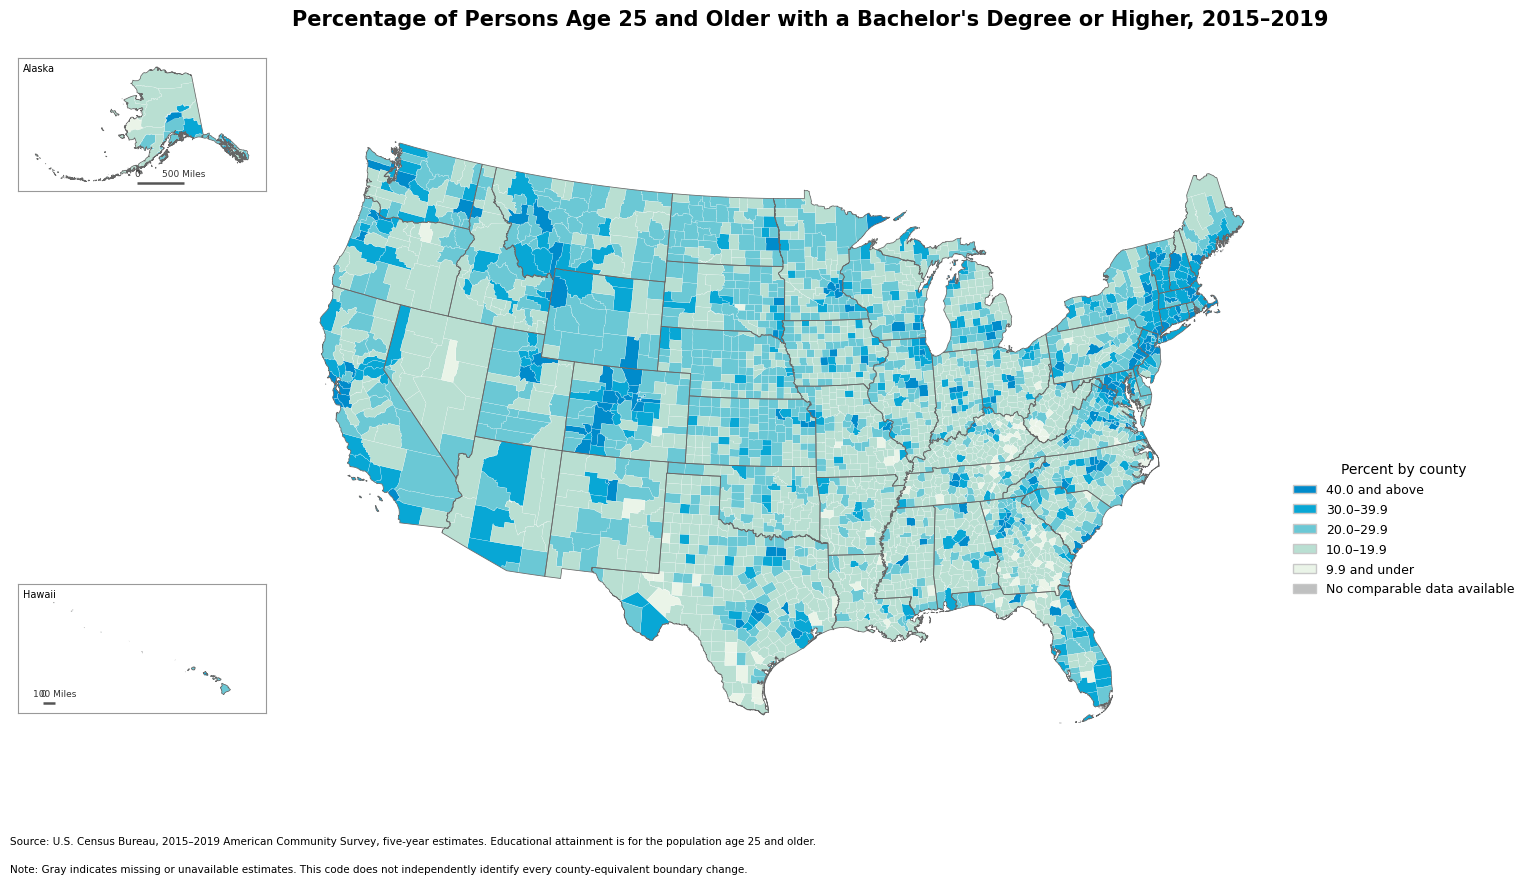

Map saved to: /content/bachelors_degree_choropleth_2015_2019.png


In [2]:
%pip install pandas geopandas matplotlib requests shapely pyogrio
import os
import io
import zipfile
import tempfile
import getpass
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ============================================================
# 1. CONFIGURATION
# ============================================================

YEAR = 2019

OUTPUT_MAP = "bachelors_degree_choropleth_2015_2019.png"
OUTPUT_CSV = "bachelors_degree_county_data_2015_2019.csv"

ACS_URL = f"https://api.census.gov/data/{YEAR}/acs/acs5"

COUNTY_BOUNDARY_URL = (
    "https://www2.census.gov/geo/tiger/GENZ2019/"
    "shp/cb_2019_us_county_500k.zip"
)

STATE_BOUNDARY_URL = (
    "https://www2.census.gov/geo/tiger/GENZ2019/"
    "shp/cb_2019_us_state_500k.zip"
)

# ACS Table B15003: Educational Attainment
TOTAL_VAR = "B15003_001E"

DEGREE_VARS = [
    "B15003_022E",  # Bachelor's degree
    "B15003_023E",  # Master's degree
    "B15003_024E",  # Professional school degree
    "B15003_025E",  # Doctorate degree
]

CLASS_ORDER = [
    "40.0 and above",
    "30.0–39.9",
    "20.0–29.9",
    "10.0–19.9",
    "9.9 and under",
    "No comparable data available",
]

COLORS = {
    "40.0 and above": "#008BCB",
    "30.0–39.9": "#08A7D5",
    "20.0–29.9": "#6BC8D5",
    "10.0–19.9": "#B9DFD2",
    "9.9 and under": "#EAF4E8",
    "No comparable data available": "#BFC0C0",
}

# Exclude territories and other non-state areas.
# Keep the 50 states and Washington, D.C.
EXCLUDED_STATE_CODES = {"60", "66", "69", "72", "78"}


# ============================================================
# 2. CENSUS API KEY
# ============================================================

API_KEY = os.getenv("CENSUS_API_KEY")

if not API_KEY:
    API_KEY = getpass.getpass(
        "Enter your U.S. Census API key: "
    ).strip()

if not API_KEY:
    raise ValueError("A Census API key is required.")


# ============================================================
# 3. DOWNLOAD AND READ SHAPEFILES
# ============================================================

def download_shapefile(url, extract_folder):
    """Download and extract a Census shapefile archive."""

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        archive.extractall(extract_folder)

    shp_files = [
        os.path.join(extract_folder, name)
        for name in os.listdir(extract_folder)
        if name.lower().endswith(".shp")
    ]

    if not shp_files:
        raise FileNotFoundError(
            f"No shapefile found in archive: {url}"
        )

    return gpd.read_file(shp_files[0])


# ============================================================
# 4. DOWNLOAD ACS COUNTY ESTIMATES
# ============================================================

def download_acs_data():
    """Retrieve county-level educational attainment estimates."""

    variables = ["NAME", TOTAL_VAR, *DEGREE_VARS]

    params = {
        "get": ",".join(variables),
        "for": "county:*",
        "in": "state:*",
        "key": API_KEY,
    }

    response = requests.get(
        ACS_URL,
        params=params,
        timeout=120,
    )

    response.raise_for_status()

    content_type = response.headers.get(
        "Content-Type", ""
    ).lower()

    if "json" not in content_type:
        raise RuntimeError(
            "The Census API did not return JSON data. "
            f"HTTP status: {response.status_code}. "
            f"Response preview: {response.text[:300]}"
        )

    try:
        payload = response.json()
    except ValueError as exc:
        raise RuntimeError(
            "Unable to parse the Census API response as JSON."
        ) from exc

    if not isinstance(payload, list) or len(payload) < 2:
        raise RuntimeError(
            f"Unexpected Census API response: {str(payload)[:300]}"
        )

    df = pd.DataFrame(payload[1:], columns=payload[0])

    # Preserve leading zeros in state and county FIPS codes.
    df["GEOID"] = (
        df["state"].astype(str).str.zfill(2)
        + df["county"].astype(str).str.zfill(3)
    )

    for column in [TOTAL_VAR, *DEGREE_VARS]:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

    # Sum estimates for bachelor's degree or higher.
    df["Degree_Count"] = df[DEGREE_VARS].sum(
        axis=1,
        min_count=len(DEGREE_VARS),
    )

    valid_denominator = (
        df[TOTAL_VAR].notna()
        & (df[TOTAL_VAR] > 0)
        & df["Degree_Count"].notna()
    )

    df["Percent_Bachelors_Or_Higher"] = float("nan")

    df.loc[
        valid_denominator,
        "Percent_Bachelors_Or_Higher",
    ] = (
        df.loc[valid_denominator, "Degree_Count"]
        / df.loc[valid_denominator, TOTAL_VAR]
        * 100
    )

    return df[
        [
            "GEOID",
            "NAME",
            "Percent_Bachelors_Or_Higher",
        ]
    ].copy()


# ============================================================
# 5. ASSIGN FIXED LEGEND CATEGORIES
# ============================================================

def assign_category(value):
    """Assign an estimate to one of five percentage classes."""

    if pd.isna(value):
        return "No comparable data available"
    elif value >= 40:
        return "40.0 and above"
    elif value >= 30:
        return "30.0–39.9"
    elif value >= 20:
        return "20.0–29.9"
    elif value >= 10:
        return "10.0–19.9"
    else:
        return "9.9 and under"


# ============================================================
# 6. MAP DRAWING HELPERS
# ============================================================

def draw_counties(ax, geo_df):
    """Draw county polygons using fixed category colors."""

    for category in CLASS_ORDER:
        subset = geo_df[
            geo_df["Map_Category"] == category
        ]

        if not subset.empty:
            subset.plot(
                ax=ax,
                color=COLORS[category],
                edgecolor="white",
                linewidth=0.12,
                zorder=1,
            )


def draw_state_boundaries(ax, state_df):
    """Draw state boundaries above county polygons."""

    if not state_df.empty:
        state_df.boundary.plot(
            ax=ax,
            color="#666666",
            linewidth=0.55,
            zorder=3,
        )


def set_extent(ax, geo_df, padding=0.02):
    """Set map extent and remove coordinate axes."""

    if geo_df.empty:
        ax.set_axis_off()
        return

    minx, miny, maxx, maxy = geo_df.total_bounds

    xpad = (maxx - minx) * padding
    ypad = (maxy - miny) * padding

    ax.set_xlim(minx - xpad, maxx + xpad)
    ax.set_ylim(miny - ypad, maxy + ypad)
    ax.set_aspect("equal")
    ax.set_axis_off()


def style_inset(ax):
    """Show inset borders without coordinate labels or ticks."""

    ax.set_axis_on()
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.tick_params(
        axis="both",
        which="both",
        bottom=False,
        top=False,
        left=False,
        right=False,
        labelbottom=False,
        labeltop=False,
        labelleft=False,
        labelright=False,
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#999999")
        spine.set_linewidth(0.8)

    ax.set_facecolor("white")


def add_scale_bar(
    ax,
    length_miles,
    label,
    position=(0.08, 0.09),
):
    """Add an approximate scale bar to a projected inset."""

    length_m = length_miles * 1609.344

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    x = xmin + (xmax - xmin) * position[0]
    y = ymin + (ymax - ymin) * position[1]

    ax.plot(
        [x, x + length_m],
        [y, y],
        color="#555555",
        linewidth=1.8,
        solid_capstyle="butt",
        clip_on=False,
        zorder=10,
    )

    label_y = y + (ymax - ymin) * 0.035

    ax.text(
        x,
        label_y,
        "0",
        fontsize=6.5,
        ha="center",
        va="bottom",
        color="#333333",
        clip_on=False,
    )

    ax.text(
        x + length_m,
        label_y,
        label,
        fontsize=6.5,
        ha="center",
        va="bottom",
        color="#333333",
        clip_on=False,
    )


# ============================================================
# 7. CREATE MAP AND EXPORT COUNTY DATA
# ============================================================

def create_map():
    print("Downloading ACS county estimates...")
    acs_df = download_acs_data()

    print("Downloading county and state boundaries...")

    with tempfile.TemporaryDirectory() as temp_dir:
        county_dir = os.path.join(temp_dir, "counties")
        state_dir = os.path.join(temp_dir, "states")

        os.makedirs(county_dir)
        os.makedirs(state_dir)

        counties = download_shapefile(
            COUNTY_BOUNDARY_URL,
            county_dir,
        )

        states = download_shapefile(
            STATE_BOUNDARY_URL,
            state_dir,
        )

        # Keep the 50 states and Washington, D.C.
        counties = counties[
            ~counties["STATEFP"].isin(EXCLUDED_STATE_CODES)
        ].copy()

        states = states[
            ~states["STATEFP"].isin(EXCLUDED_STATE_CODES)
        ].copy()

        # Avoid NAME_x / NAME_y merge suffixes.
        if "NAME" in counties.columns:
            counties = counties.rename(
                columns={"NAME": "County_Name"}
            )

        # Join using GEOID, not names.
        counties = counties.merge(
            acs_df,
            on="GEOID",
            how="left",
            validate="one_to_one",
        )

        if "County_Name" not in counties.columns:
            counties["County_Name"] = counties["NAME"]

        counties["Map_Category"] = counties[
            "Percent_Bachelors_Or_Higher"
        ].apply(assign_category)

        # Export county data for validation or reuse.
        export_df = counties[
            [
                "GEOID",
                "County_Name",
                "Percent_Bachelors_Or_Higher",
                "Map_Category",
            ]
        ].copy()

        export_df = export_df.rename(
            columns={"County_Name": "NAME"}
        )

        export_df.to_csv(OUTPUT_CSV, index=False)

        print(
            "County data saved to: "
            + os.path.abspath(OUTPUT_CSV)
        )

        # ----------------------------------------------------
        # SEPARATE MAP PROJECTIONS
        # ----------------------------------------------------

        # Contiguous U.S.
        mainland_counties = counties[
            ~counties["STATEFP"].isin(["02", "15"])
        ].to_crs("EPSG:5070")

        mainland_states = states[
            ~states["STATEFP"].isin(["02", "15"])
        ].to_crs("EPSG:5070")

        # Alaska
        alaska_counties = counties[
            counties["STATEFP"] == "02"
        ].to_crs("EPSG:3338")

        alaska_states = states[
            states["STATEFP"] == "02"
        ].to_crs("EPSG:3338")

        # Hawaii
        hawaii_counties = counties[
            counties["STATEFP"] == "15"
        ].to_crs("EPSG:26963")

        hawaii_states = states[
            states["STATEFP"] == "15"
        ].to_crs("EPSG:26963")

        # ----------------------------------------------------
        # NON-OVERLAPPING FIGURE LAYOUT
        # ----------------------------------------------------

        fig = plt.figure(
            figsize=(16, 9.2),
            facecolor="white",
        )

        # Dedicated left column for Alaska and Hawaii.
        ax_ak = fig.add_axes(
            [0.025, 0.755, 0.155, 0.17]
        )

        ax_hi = fig.add_axes(
            [0.025, 0.20, 0.155, 0.14]
        )

        # Main map in the center.
        ax_main = fig.add_axes(
            [0.205, 0.14, 0.595, 0.73]
        )

        # Draw county fills.
        draw_counties(ax_main, mainland_counties)
        draw_counties(ax_ak, alaska_counties)
        draw_counties(ax_hi, hawaii_counties)

        # Draw state boundaries.
        draw_state_boundaries(ax_main, mainland_states)
        draw_state_boundaries(ax_ak, alaska_states)
        draw_state_boundaries(ax_hi, hawaii_states)

        # Set extents and remove easting/northing labels.
        set_extent(ax_main, mainland_counties, padding=0.015)
        set_extent(ax_ak, alaska_counties, padding=0.08)
        set_extent(ax_hi, hawaii_counties, padding=0.20)

        # Restore only the inset frames.
        style_inset(ax_ak)
        style_inset(ax_hi)

        # Illustrative scale bars; validate before publication.
        add_scale_bar(
            ax_ak,
            length_miles=500,
            label="500 Miles",
            position=(0.48, 0.06),
        )

        add_scale_bar(
            ax_hi,
            length_miles=100,
            label="100 Miles",
            position=(0.10, 0.08),
        )

        # Inset labels.
        ax_ak.text(
            0.02, 0.96, "Alaska",
            transform=ax_ak.transAxes,
            fontsize=7,
            ha="left",
            va="top",
        )

        ax_hi.text(
            0.02, 0.96, "Hawaii",
            transform=ax_hi.transAxes,
            fontsize=7,
            ha="left",
            va="top",
        )

        # ----------------------------------------------------
        # TITLE
        # ----------------------------------------------------

        fig.suptitle(
            "Percentage of Persons Age 25 and Older with a "
            "Bachelor's Degree or Higher, 2015–2019",
            fontsize=15,
            fontweight="bold",
            x=0.52,
            y=0.965,
            ha="center",
        )

        # ----------------------------------------------------
        # LEGEND
        # ----------------------------------------------------

        legend_handles = [
            Patch(
                facecolor=COLORS[category],
                edgecolor="#C8C8C8",
                label=category,
            )
            for category in CLASS_ORDER
        ]

        fig.legend(
            handles=legend_handles,
            title="Percent by county",
            loc="center left",
            bbox_to_anchor=(0.815, 0.40),
            frameon=False,
            fontsize=9,
            title_fontsize=10,
            labelspacing=0.55,
            handlelength=1.8,
        )

        # ----------------------------------------------------
        # SOURCE AND NOTE
        # ----------------------------------------------------

        fig.text(
            0.02,
            0.055,
            "Source: U.S. Census Bureau, 2015–2019 American "
            "Community Survey, five-year estimates. "
            "Educational attainment is for the population "
            "age 25 and older.",
            ha="left",
            va="bottom",
            fontsize=7.5,
        )

        fig.text(
            0.02,
            0.025,
            "Note: Gray indicates missing or unavailable estimates. "
            "This code does not independently identify every "
            "county-equivalent boundary change.",
            ha="left",
            va="bottom",
            fontsize=7.5,
        )

        # ----------------------------------------------------
        # SAVE AND DISPLAY
        # ----------------------------------------------------

        fig.savefig(
            OUTPUT_MAP,
            dpi=300,
            facecolor="white",
        )

        plt.show()
        plt.close(fig)

        print("Map saved to:", os.path.abspath(OUTPUT_MAP))


# ============================================================
# 8. RUN
# ============================================================

if __name__ == "__main__":
    create_map()